In [1]:
import numpy as np

def gini(labels):
    if len(labels) == 0:
        return 0.0
    share_late = np.mean(labels)
    return 1 - share_late ** 2 - (1 - share_late) ** 2

def weighted_gini(left, right):
    number_of_trips = len(left) + len(right)
    return (len(left) * gini(left) + len(right) * gini(right)) / number_of_trips

# The seven trips: 1 = yes, 0 = no
rain      = np.array([1, 1, 1, 1, 0, 0, 0])
rush_hour = np.array([1, 1, 0, 0, 1, 0, 0])
late      = np.array([1, 1, 1, 0, 1, 0, 0])

print(late[rain == 1])
print(round(gini(late), 3))
print(round(weighted_gini(late[rain == 1], late[rain == 0]), 3))
print(round(weighted_gini(late[rush_hour == 1], late[rush_hour == 0]), 3))

[1 1 1 0]
0.49
0.405
0.214


**Pseudo-code**

```
gini(leaf) = 1 − share_late² − (1 − share_late)²
weighted_gini(left, right) = (n_left × gini(left) + n_right × gini(right)) / n
store the 7 trips: rain, rush hour, late
print the Gini of all 7 trips, then the weighted Gini of each question
```

In [2]:
# 2,000 simulated trips (made-up data, generated here)
rng = np.random.default_rng(seed=0)
number_of_trips = 2000
distance    = rng.uniform(1, 15, number_of_trips)       # km
rush_hour   = rng.random(number_of_trips) < 0.3
rain        = rng.random(number_of_trips) < 0.25
temperature = rng.normal(5, 10, number_of_trips)       # °C, no effect on lateness: pure noise
score = -3 + 0.25 * distance + 1.5 * rush_hour + 0.8 * rain
probability_late = 1 / (1 + np.exp(-score))            # the S-curve from Day 2
late = (rng.random(number_of_trips) < probability_late).astype(int)

thresholds = np.arange(1.5, 15, 0.5)
weighted_gini_by_threshold = [weighted_gini(late[distance < t], late[distance >= t]) for t in thresholds]
best_threshold = thresholds[np.argmin(weighted_gini_by_threshold)]

print(round(late.mean(), 3), round(gini(late), 3))
print(best_threshold, round(min(weighted_gini_by_threshold), 3))

0.419 0.487
8.5 0.422


**Pseudo-code**

```
simulate 2,000 trips: distance, rush hour, rain, temperature (noise)
probability of late = S-curve(−3 + 0.25 × distance + 1.5 × rush hour + 0.8 × rain)
draw late or on time with that probability
for each distance threshold from 1.5 to 14.5 km: weighted Gini of the split
print the share of late trips, the Gini of all trips, the best threshold and its weighted Gini
```

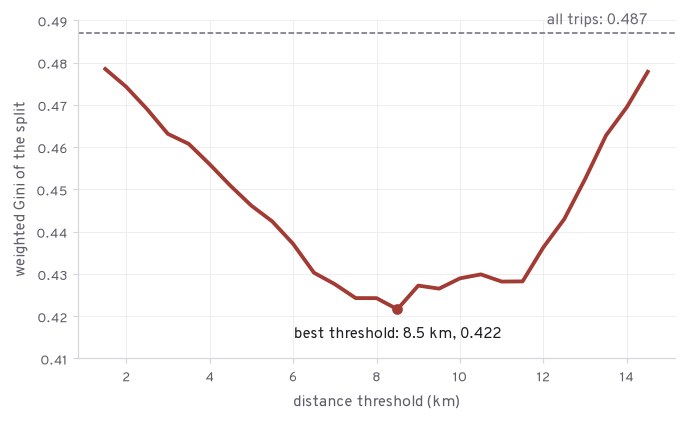

In [3]:
import sys
sys.path.insert(0, "../../../style")
from charte import charger_charte, sauver_clair_et_sombre  # shared style: fonts, colours, light and dark export
import matplotlib.pyplot as plt

charger_charte()

def draw(colours):
    figure, axis = plt.subplots(figsize=(7, 4))
    axis.axhline(gini(late), color=colours["trait"], linewidth=1, linestyle="--")
    axis.annotate(f"all trips: {gini(late):.3f}", (14.5, gini(late)), xytext=(0, 6),
                  textcoords="offset points", ha="right", color=colours["trait"])
    axis.plot(thresholds, weighted_gini_by_threshold, color=colours["accent"], linewidth=2.5)
    lowest = min(weighted_gini_by_threshold)
    axis.scatter([best_threshold], [lowest], color=colours["accent"], zorder=3)
    axis.annotate(f"best threshold: {best_threshold} km, {lowest:.3f}", (best_threshold, lowest), xytext=(0, -10), va="top",
                  textcoords="offset points", ha="center", color=colours["texte"])
    axis.set_ylim(0.41, None)   # room under the lowest point for its label
    axis.set_xlabel("distance threshold (km)")
    axis.set_ylabel("weighted Gini of the split")
    return figure

sauver_clair_et_sombre(draw, "gini_by_threshold")

**Pseudo-code**

```
load the shared style (fonts, colours)
draw the Gini of all trips as a dashed grey line
draw the weighted Gini for each threshold in the accent colour
mark and label the best threshold
save two versions: _clair.png (light) and _sombre.png (dark)
```

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

features = np.column_stack([distance, rush_hour, rain, temperature])
features_train, features_test, late_train, late_test = train_test_split(features, late, test_size=0.3, random_state=0)

tree = DecisionTreeClassifier(random_state=0).fit(features_train, late_train)
forest = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0).fit(features_train, late_train)

# accuracy = share of trips correctly predicted
print("tree  ", round(tree.score(features_train, late_train), 3), round(tree.score(features_test, late_test), 3), tree.get_n_leaves())
print("forest", round(forest.score(features_train, late_train), 3), round(forest.score(features_test, late_test), 3), round(forest.oob_score_, 3))

tree   1.0 0.662 394
forest 1.0 0.703 0.661


**Pseudo-code**

```
features: distance, rush hour, rain, temperature
split the trips at random: 70% to train, 30% to test
fit one deep tree, then a forest of 500 trees (with the out-of-bag score)
print the accuracy on train and on test; the tree's number of leaves; the forest's out-of-bag accuracy
```